#**Questão de negócio**

Uma empresa está interessada em verificar se a remuneração(salario) dos funcionarios está de acordo com as politicas da empresa.


Para isso uma amostra de 46 colaboradores foi disponibilisada

* Pergunta de negócio: O salario muda de acordo com os anos de educação superior
* Se muda, é possivel prever o salario apartir de um modelo ?

In [1]:
#manipulação dos dados
import pandas as pd

#graficos
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

#statística
import statsmodels.api as sm

In [5]:
df = pd.read_csv('/content/base_funcionarios_v3.csv',sep=',',index_col='Unnamed: 0')
display(df)

,Salario,Anos_Educ_Superior,Tempo_Empresa,Tempo_de_Carreira
0,5517.4,3,3,9.777079
1,6399.9,4,6,3.765998
2,6206.7,6,3,7.926264
3,6060.6,4,5,2.233497
4,6122.7,2,9,26.821842
5,6955.0,5,9,21.405828
6,7643.0,4,6,10.781766
7,6210.2,2,8,10.424700
8,5761.0,9,15,28.089606
9,8086.9,6,14,21.113964


In [6]:
df.isna().sum()

,0
Salario,0
Anos_Educ_Superior,0
Tempo_Empresa,0
Tempo_de_Carreira,0


In [9]:
df.describe().round(2)

,Salario,Anos_Educ_Superior,Tempo_Empresa,Tempo_de_Carreira
count,46.00,46.00,46.00,46.00
mean,6969.80,5.07,10.33,21.33
std,1924.87,2.84,7.60,15.68
min,4139.50,0.00,0.00,1.23
25%,5818.35,4.00,5.25,9.62
50%,6394.75,5.00,8.50,17.69
75%,7972.40,6.00,17.25,29.77
max,12118.10,12.00,27.00,67.86


In [8]:
# transforma todos os numero em positivo
df['Tempo_de_Carreira'] = df['Tempo_de_Carreira'].abs()

##Correlação linear de Person

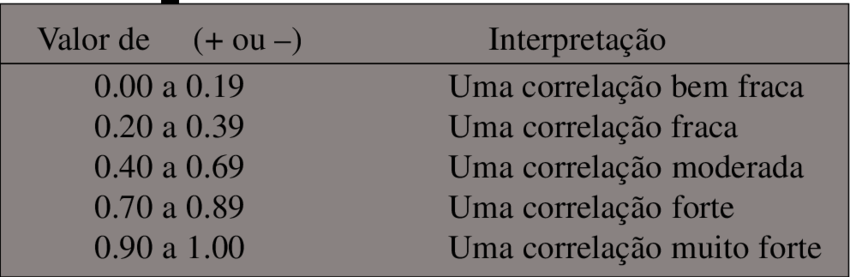

In [10]:
df.corr()

,Salario,Anos_Educ_Superior,Tempo_Empresa,Tempo_de_Carreira
Salario,1.000000,0.776992,0.765173,0.707899
Anos_Educ_Superior,0.776992,1.000000,0.607486,0.617124
Tempo_Empresa,0.765173,0.607486,1.000000,0.937629
Tempo_de_Carreira,0.707899,0.617124,0.937629,1.000000


<Axes: xlabel='Anos_Educ_Superior', ylabel='Salario'>

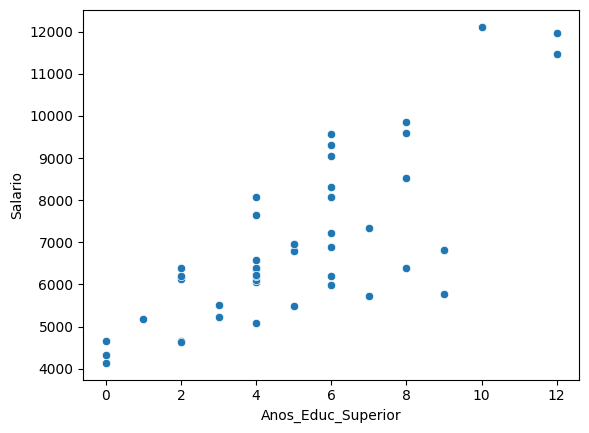

In [11]:
sns.scatterplot(df, x='Anos_Educ_Superior', y='Salario')

<Axes: xlabel='Tempo_Empresa', ylabel='Salario'>

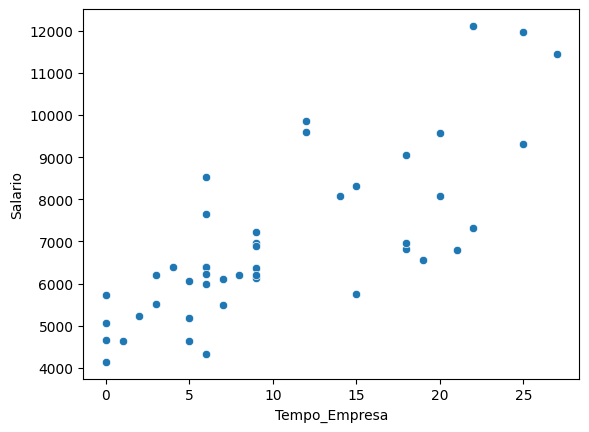

In [12]:
sns.scatterplot(df, x='Tempo_Empresa', y='Salario')

<Axes: xlabel='Tempo_de_Carreira', ylabel='Salario'>

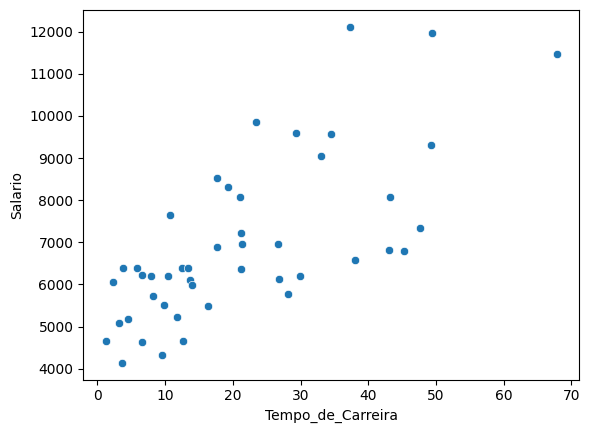

In [14]:
sns.scatterplot(df, x='Tempo_de_Carreira', y='Salario')

<Axes: >

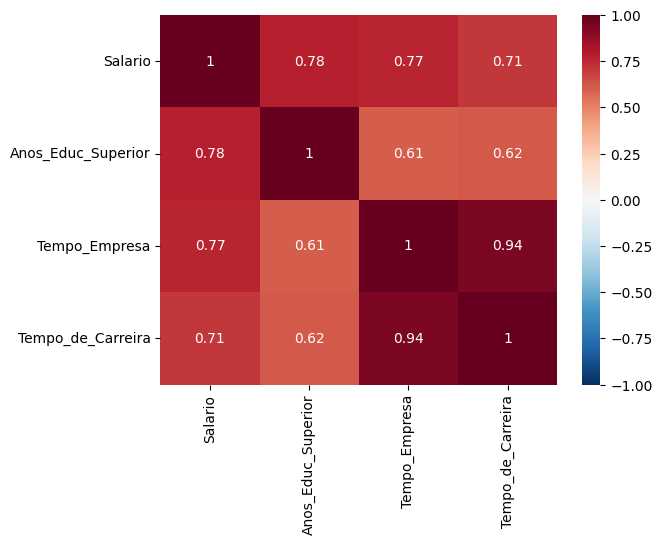

In [15]:
sns.heatmap(
    df.corr(),
    vmin=-1,vmax=1,
    cmap= 'RdBu_r',
    annot=True
)

In [16]:
#variavel alvo / target
y = df['Salario']

#variaveis independentes / explicativas
df['intercepto'] = 1
x = df[['Anos_Educ_Superior','intercepto','Tempo_Empresa','Tempo_de_Carreira']]

In [17]:
#Ajuste do modelo
# minimos quadrados ordinarios
modelo = sm.OLS(y,x)

In [18]:
#treinamento
resultado = modelo.fit()

In [19]:
print(resultado.summary())

                            OLS Regression Results                            
Dep. Variable:                Salario   R-squared:                       0.749
Model:                            OLS   Adj. R-squared:                  0.731
Method:                 Least Squares   F-statistic:                     41.83
Date:                Thu, 19 Nov 2026   Prob (F-statistic):           1.11e-12
Time:                        18:04:06   Log-Likelihood:                -380.83
No. Observations:                  46   AIC:                             769.7
Df Residuals:                      42   BIC:                             777.0
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Anos_Educ_Superior   349.7840     66

In [ ]:
df['Novo Salario'] = df['Anos_Educ_Superior'] * 526.73 + 4301.80 + df['Tempo_Empresa'] * 117.66
display(df[['Salario','Novo Salario']])

,Salario,Novo Salario
id,,
1,5517.4,6234.97
2,6399.9,7114.68
3,6206.7,7815.16
4,6060.6,6997.02
5,6122.7,6414.20
6,6955.0,7994.39
7,7643.0,7114.68
8,6210.2,6296.54
9,5761.0,10807.27
